In [ ]:

import numpy as np

## indexing & slicing
* 1차원 배열의 인덱싱·슬라이싱 : **`[]`**
* 2차원 배열의 인덱싱·슬라이싱 : **`[행, 열]`**
* 3차원 배열의 인덱싱·슬라이싱 : **`[면, 행, 열]`**

### 1차원 배열

In [ ]:
# -----------------------------
# 1차원 배열 인덱싱 (0번부터 시작)
# -----------------------------
arr = np.array([1,2,3,4,5])
print(arr)

print(arr[0])   # 1 (맨 앞)
print(arr[2])   # 3
print(arr[4])   # 5 (맨 뒤)

In [ ]:
# -----------------------------
# 마이너스 인덱싱 (뒤에서부터 -1)
# -----------------------------

print(arr[-1])  # 5 (맨 뒤)
print(arr[-2])  # 4
print(arr[-5])  # 1 (맨 앞)

In [ ]:
# -----------------------------
# 슬라이싱 [시작:끝]  (끝 번호는 포함 안 함)
# -----------------------------

print(arr[:])    # [1 2 3 4 5] 전체
print(arr[1:3])  # [2 3]
print(arr[:3])   # [1 2 3]
print(arr[3:])   # [4 5]

In [ ]:
# -----------------------------
# 슬라이싱 심화 [시작:끝:간격]
# -----------------------------

print(arr[::2])   # [1 3 5]  2칸 간격
print(arr[::-1])  # [5 4 3 2 1]  역순(거꾸로)

### 2차원 배열
`arr[행, 열]` 형태로 선택한다. `:` 는 '전체'를 의미한다. (아래 그림에서 주황색이 선택된 값)

In [ ]:
arr_2d = np.array([[1,2,3],
                   [4,5,6]])
print(arr_2d)


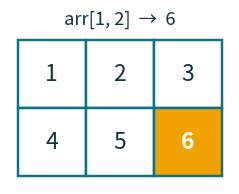

In [ ]:
# arr[1,2] → 1행 2열의 값

arr_2d[1,2]      # 6

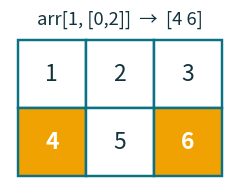

In [ ]:
# arr[1,[0,2]] → 1행에서 0열,2열만 (fancy)

arr_2d[1,[0,2]]  # [4 6]

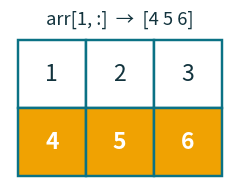

In [ ]:
# arr[1,:] → 1행 전체

arr_2d[1,:]      # [4 5 6]

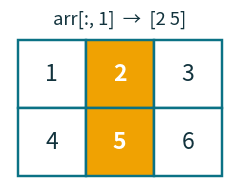

In [ ]:
# arr[:,1] → 모든 행의 1열 (세로 한 줄)

arr_2d[:,1]      # [2 5]

### 3차원 배열
`arr[면, 행, 열]` 형태로 선택한다. 3차원은 2차원(면)이 여러 장 쌓인 구조다.

In [ ]:
arr_3d = np.array([[[1,2,3],[4,5,6]],
                   [[7,8,9],[10,11,12]],
                   [[13,14,15],[16,17,18]]])
print(arr_3d)


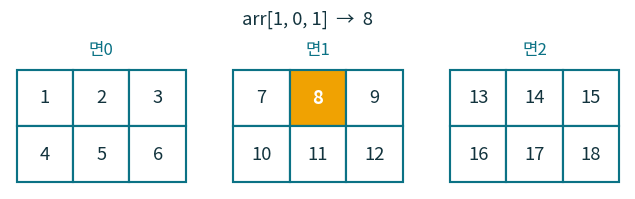

In [ ]:
# arr[1,0,1] → 1면 0행 1열 (값 하나 콕 집기)

arr_3d[1,0,1]    # 8

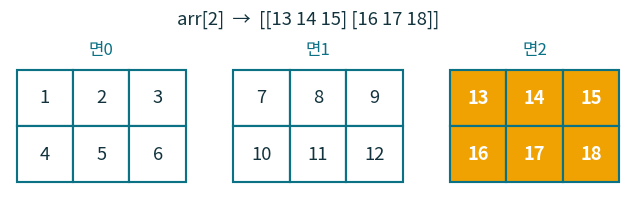

In [ ]:
# arr[2] → 2면 전체 (= arr[2,:,:])

arr_3d[2]        # [[13 14 15] [16 17 18]]

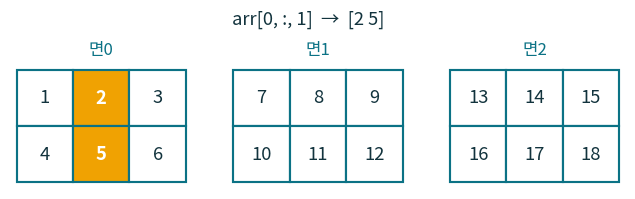

In [ ]:
# arr[0,:,1] → 0면 모든 행의 1열 (2차원 슬라이싱과 같은 방식)

arr_3d[0,:,1]    # [2 5]

### 💡 3차원은 실무에서 언제 쓸까 — 컬러 이미지
* 컬러 이미지는 **`(높이, 너비, 3)` 형태의 3차원 배열**이다.
* **한 픽셀 = `[R, G, B]` 값 하나의 묶음** (각 값 0~255). 예: `[255,0,0]`=빨강, `[255,255,0]`=노랑, `[0,0,0]`=검정
* 축 읽는 법은 2차원 `[행, 열]` 과 똑같다 → **`[행(세로), 열(가로), 색]` · 첫 번째가 세로(행)**
* 실무에서는 인덱스를 하나씩 찍기보다 **슬라이싱으로 채널을 통째로** 뽑는다. (`img[:, :, 0]` = R 채널)
* 딥러닝·영상으로 가면 여기에 batch·프레임이 더해져 4차원이 된다.

In [ ]:
# 2x2 크기의 작은 컬러 이미지 (높이2, 너비2, 채널3=RGB)
# 각 픽셀이 [R, G, B] 값을 가짐
img = np.array([[[255,0,0],  [0,255,0]],
                [[0,0,255],  [255,255,0]]])
print('shape:', img.shape)   # (2, 2, 3)

print('맨 윗줄 왼쪽 픽셀:', img[0,0])   # [255 0 0] = 빨강

# 채널별로 뽑기 (마지막 축을 고정)
print('R 채널\n', img[:,:,0])   # [[255 0] [0 255]]
print('G 채널\n', img[:,:,1])
print('B 채널\n', img[:,:,2])

> **📌 참고 — 이미지 배열 순서는 라이브러리마다 다르다**
> 새 라이브러리를 쓸 땐 어떤 형태를 쓰는지 먼저 확인하세요.
>
> | 구분 | 축 순서 | 색 순서 |
> |---|---|---|
> | NumPy · matplotlib · PIL | `(높이, 너비, 채널)` | **RGB** |
> | OpenCV (`cv2`) | `(높이, 너비, 채널)` | **BGR** ⚠️ |
> | PyTorch (딥러닝) | `(채널, 높이, 너비)` | RGB |
>
> * **채널 위치**: 대부분 마지막(채널 last)이지만 PyTorch는 맨 앞(채널 first).
> * **색 순서**: `cv2` 는 **BGR** 로 읽어서, 그대로 matplotlib에 넣으면 빨강↔파랑이 뒤바뀐다.
>   → `cv2.cvtColor(img, cv2.COLOR_BGR2RGB)` 로 변환.
> * **높이·너비 순서**는 대체로 어디서나 (높이 먼저, 너비 나중)로 동일하다.

## fancy indexing
* 인덱스 **리스트**를 넣어 원하는 위치만 골라 뽑기
* (참고) fancy 인덱싱은 원본을 참조하지 않고 **새 배열(copy)** 을 돌려준다.

In [ ]:
arr = np.array([100,101,102,103,104])
print(arr)
# 0,2,4번 인덱스의 값만 뽑기

print(arr[[0,2,4]])   # [100 102 104]

## boolean indexing
* True/False 배열로 True인 위치만 뽑기 (조건 필터링에 사용)
    * `arr[조건]`
    * `np.where(조건, x, y)` → 조건이 True면 x, False면 y
* (참고) boolean 인덱싱도 **새 배열(copy)** 을 돌려준다.

In [ ]:
arr = np.array([100,101,102,103,104])
bool_idx = [True, False, True, False, True]
print(arr)
print(bool_idx)
# True인 위치만 뽑기

print(arr[bool_idx])   # [100 102 104]

In [ ]:
# -----------------
# 홀수만 선택하기
# 조건식은 True/False 배열을 만든다
# -----------------
nums = np.array([100,103,102,101,109])
print(nums)

cond = (nums % 2 == 1)
print(cond)          # [False  True False  True  True]
print(nums[cond])    # [103 101 109]

In [ ]:
# -----------------
# np.where(조건, x, y) — 홀/짝 라벨 배열 만들기
# -----------------
nums = np.array([100,103,102,101,109])

print(np.where(nums % 2 == 1, '홀', '짝'))   # ['짝' '홀' '짝' '홀' '홀']

In [ ]:
# -----------------
# np.where 숫자 변환 — 음수는 0으로 (ReLU 맛보기)
# -----------------
arr = np.array([-3, 5, -1, 8])

print(np.where(arr < 0, 0, arr))   # [0 5 0 8]

### 2차원 조건 필터링 (실전)
조건을 주면 2차원 배열에서도 True인 값만 **1차원으로** 뽑을 수 있다.

In [ ]:
# 3명 × 2과목 점수에서 60점 이상만 뽑기
scores = np.array([[80, 55],
                   [90, 40],
                   [70, 95]])
print(scores)

print(scores >= 60)         # True/False 2차원 배열
print(scores[scores >= 60])  # [80 90 70 95]

## 배열 복사 (copy vs 참조)
* **슬라이싱**한 배열은 원본을 **참조(view)** 한다 → 슬라이싱 배열을 수정하면 원본도 바뀜
* 원본을 지키려면 **`배열객체.copy()`** 로 복사해서 사용
* (참고) fancy·boolean 인덱싱은 반대로 처음부터 copy를 돌려줌

In [ ]:
# -----------------
# 슬라이싱은 원본을 참조 → 수정하면 원본도 바뀜
# -----------------
arr1 = np.array([1,2,3,4,5])
arr2 = arr1[:3]
print('arr1:', arr1)
print('arr2:', arr2)
print('--- arr2[0]을 100으로 수정 ---')

arr2[0] = 100
print('arr1:', arr1)   # [100 2 3 4 5]  원본도 바뀜!
print('arr2:', arr2)   # [100 2 3]

In [ ]:
# -----------------
# copy()로 복사하면 원본은 그대로
# -----------------
arr1 = np.array([1,2,3,4,5])
arr2 = arr1[:3].copy()
print('arr1:', arr1)
print('arr2:', arr2)
print('--- arr2[0]을 100으로 수정 ---')

arr2[0] = 100
print('arr1:', arr1)   # [1 2 3 4 5]  원본 그대로!
print('arr2:', arr2)   # [100 2 3]

---
## 🧩 실습 예제 · 미션 · 과제
인덱싱 · 슬라이싱 · 조건 필터 · copy 를 실전처럼 연습합니다.

### 예제 1) 성적표에서 골라 뽑기
행=학생(3명), 열=과목(국·영·수). 인덱싱/슬라이싱으로 원하는 부분을 뽑아보세요.

In [ ]:
scores = np.array([[80, 90, 70],
                   [60, 85, 95],
                   [90, 75, 80]])
# ① 1번 학생(인덱스1)의 점수 전체
# ② 모든 학생의 수학(2열) 점수

print('1번 학생 :', scores[1])       # [60 85 95]
print('수학 점수 :', scores[:,2])    # [70 95 80]

### 예제 2) 조건 필터 — 60점 이상만
boolean 인덱싱으로 60점 이상 점수만 뽑아보세요.

In [ ]:
# 힌트: scores[scores >= 60]

print(scores[scores >= 60])   # 60 이상 값만 1차원으로

### 예제 3) 합격/불합격 라벨
`np.where` 로 60점 이상은 '합격', 미만은 '불합격'으로 바꿔보세요.

In [ ]:
# 힌트: np.where(scores >= 60, '합격', '불합격')

print(np.where(scores >= 60, '합격', '불합격'))

### 미션) 슬라이싱 도전
1. 배열을 **거꾸로** 만들기
2. **짝수 인덱스**의 값만 뽑기
3. 2차원 배열에서 **가운데 부분만** 잘라내기 (이미지 자르기 맛보기)

In [ ]:
# -------------------------------
# [미션] 1: 거꾸로  2: 짝수 인덱스
# -------------------------------
arr = np.array([10, 20, 30, 40, 50])

print(arr[::-1])   # [50 40 30 20 10]
print(arr[::2])    # [10 30 50]

In [ ]:
# -------------------------------
# [미션] 3: 4x4 배열의 가운데 2x2만 잘라내기
# 힌트: img[1:3, 1:3]
# -------------------------------
img = np.arange(1, 17).reshape(4, 4)
print(img)

print('가운데 2x2\n', img[1:3, 1:3])
# [[ 6  7]
#  [10 11]]

### 과제) 학생 성적 데이터 종합 선택
아래 요구사항을 순서대로 해결하세요. (인덱싱 ~ 슬라이싱 ~ 조건필터 ~ copy 종합)

1. 학생 6명 × 과목 4개 점수를 20~100 랜덤 정수로 생성 (`seed(0)` 고정)
2. **인덱싱**으로 3번 학생(인덱스 3)의 점수를 조회
3. **슬라이싱**으로 앞 3명의 점수만 추출
4. **조건 필터**로 평균 60 미만인 학생을 찾기 (힌트: `scores.mean(axis=1)`)
5. `np.where` 로 각 점수를 합격(60↑)/불합격 표로 만들기
6. 원본을 지키려면 왜 `copy()` 가 필요한지 주석으로 설명

In [ ]:
# -------------------------------
# [과제] 학생 성적 데이터 종합 선택 (1~6번)
# -------------------------------